# Case 1 — notebook_6: Metrik CV-nya yang Salah, Bukan Modelnya

`notebook_5` disubmit: **LB 0,2063**. Prediksinya berkorelasi 0,978 dengan notebook_3
(LB 0,1996) dan `lb_est`-nya memperkirakan 0,1942. Meleset +0,012, dan ini kegagalan
prediksi kedua setelah notebook_2.

| # | CV lama | prediksi LB | **LB aktual** | `bias_rnd` |
|---|---|---|---|---|
| notebook_1 | 0,1826 | 0,1953 | 0,2005 | +0,076 |
| notebook_2 | 0,1789 | 0,1902 | **0,2262** | +0,137 |
| notebook_3 | 0,1855 | 0,1988 | **0,1996** | +0,047 |
| notebook_5 | 0,1790 | 0,1942 | **0,2063** | +0,056 |

Dua kegagalan, dua diagnosis berbeda (fitur bocor; lalu bobot blend overfit), dan dua-duanya
menambal gejala. Notebook ini mencari penyebab yang sama-sama menjelaskan keduanya — dan
menemukannya bukan di model, tapi di **fungsi evaluasi yang kami pakai sendiri**.

---
## 1. Setup

Pipeline dipecah jadi modul supaya tiap eksperimen bisa mengambil hasil model dari cache
(`cache/`, tidak di-commit) alih-alih melatih ulang: `lab_common.py` (data, metrik, fitur,
post-processing), `lab_models.py` (LightGBM + cache OOF), `lab_cnn.py` (model deep),
`lab_group.py` (classifier pasangan), `fastscore.py` (skor cepat untuk pencarian bobot).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("lab"))   # modul pipeline ada di lab/
import numpy as np, pandas as pd, json, warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt, seaborn as sns
import lab_common as C, lab_models as M
from fastscore import Scorer, Post

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110; pd.set_option("display.width", 200)

Ftr, Fte = C.get_feats()
print("train", Ftr.shape, " test", Fte.shape)
print("record depth-bulat:  train %.0f%%   test %.0f%%" % (C.rnd_tr.mean()*100, C.rnd_te.mean()*100))

train (10505, 196)  test (2300, 196)
record depth-bulat:  train 32%   test 51%


---
## 2. Penyebabnya: pseudo-event melebur gempa, dan itu merusak pembobotan metrik

Dataset tidak punya `event_id`, jadi sejak `notebook_1` event direkonstruksi dengan
`groupby(["depth_km","magnitude"])`. Di sisi depth-desimal rekonstruksi itu bagus (98%
murni). Di sisi depth-**bulat** ia runtuh: semua record `depth = 10.0` yang kebetulan
bermagnitudo sama dilebur jadi **satu** pseudo-event — sampai **401 record**.

EB-TWMAE menimbang **per event**. Jadi pseudo-event raksasa bermagnitudo 5,1 dapat bobot
1,0 di CV, padahal di leaderboard ia sebenarnya ~50 gempa terpisah dengan total bobot 50.
Sebaliknya pseudo-event kecil bermagnitudo 6,8 (3 record) dapat bobot 2,5 di kedua tempat.

Akibatnya CV **melebih-lebihkan bobot ekor** di sisi depth-bulat.

In [2]:
df = pd.DataFrame({"ev": C.ev, "y": C.y, "rnd": C.rnd_tr})
g = df.groupby("ev").agg(n=("y","size"), m=("y","first"), rnd=("rnd","first"))
w = C.mag_weight(g.m.values)
rows=[]
for lbl, msk in [("depth desimal", (~g.rnd).values), ("depth bulat", g.rnd.values)]:
    ww, mm, nn = w[msk], g.m.values[msk], g.n.values[msk]
    cvw = ww/ww.sum(); rlw = (ww*nn)/(ww*nn).sum()
    rows.append(dict(subset=lbl, n_pseudo_event=int(msk.sum()), max_record_per_event=int(nn.max()),
                     bobot_M55_CV=round(cvw[mm>=5.5].sum(),3), bobot_M55_riil=round(rlw[mm>=5.5].sum(),3),
                     bobot_M65_CV=round(cvw[mm>=6.5].sum(),3), bobot_M65_riil=round(rlw[mm>=6.5].sum(),3)))
display(pd.DataFrame(rows))
print("Di sisi depth-bulat, CV menaruh bobot 3x lipat pada ekor M>=6,5 dibanding realitas.")

,subset,n_pseudo_event,max_record_per_event,bobot_M55_CV,bobot_M55_riil,bobot_M65_CV,bobot_M65_riil
0,depth desimal,672,93,0.243,0.258,0.024,0.012
1,depth bulat,233,401,0.891,0.638,0.155,0.052


Di sisi depth-bulat, CV menaruh bobot 3x lipat pada ekor M>=6,5 dibanding realitas.


Inilah mekanisme tunggal yang menjelaskan **semua** anomali sebelumnya:

- "CV selalu membaik kalau prediksi ekor didorong naik" — memang, karena CV over-weight ekor.
- `notebook_2` (fitur grup di-mask) menaikkan prediksi subset bulat -> CV bagus, LB jeblok.
- `notebook_5` (bobot blend per-subset, dipilih dengan mengoptimalkan `lb_est`) mendorong
  varians sisi bulat naik (sd 0,384 -> 0,447) -> CV bagus, LB jeblok.

Keduanya bukan overfitting biasa. Keduanya **berhasil mengoptimalkan target yang salah**.

---
## 3. Perbaikan: metrik dengan event yang dipecah realistis

Di test, 745 dari 2.300 record ada di `depth = 10.0`. Dengan ~8 record per gempa (sama
seperti sisi desimal), itu ~90 gempa, bukan satu. Jadi pseudo-event depth-bulat **dangkal**
dipecah acak jadi potongan ~8 record, dirata-ratakan atas 8 undian.

Depth >= 100 km **tidak** dipecah — di sana grupnya 67–100% murni, jadi memang sudah event
nyata. Hasilnya `cv_real`, `part_real`, `lb_real` di `lab_common.py`.

In [3]:
oofA,_ = M.cached("regA", None); oofB,_ = M.cached("regB", None)
rows=[]
for ar in [0.85, 0.95, 1.00, 1.05, 1.15, 1.30]:
    o = C.expand_subset(C.smooth_gen(0.65*oofA + 0.35*oofB, C.d_tr, 0.95, 0.0), C.d_tr, 1.15, ar)
    rows.append(dict(alpha_rnd=ar, rnd_CV_lama=round(C.part_score(o,False),4),
                     rnd_REALISTIS=round(C.part_real(o,False),4)))
R = pd.DataFrame(rows); display(R)
print("CV lama: monoton membaik sampai 1,15 -> menyuruh kita memperbesar varians.")
print("Metrik realistis: ada optimum interior di ~1,05 -> persis arah yang ditunjukkan LB.")

,alpha_rnd,rnd_CV_lama,rnd_REALISTIS
0,0.85,0.2682,0.2405
1,0.95,0.2513,0.2309
2,1.00,0.2455,0.2284
3,1.05,0.2415,0.2274
4,1.15,0.2393,0.2300
5,1.30,0.2477,0.2434


CV lama: monoton membaik sampai 1,15 -> menyuruh kita memperbesar varians.
Metrik realistis: ada optimum interior di ~1,05 -> persis arah yang ditunjukkan LB.


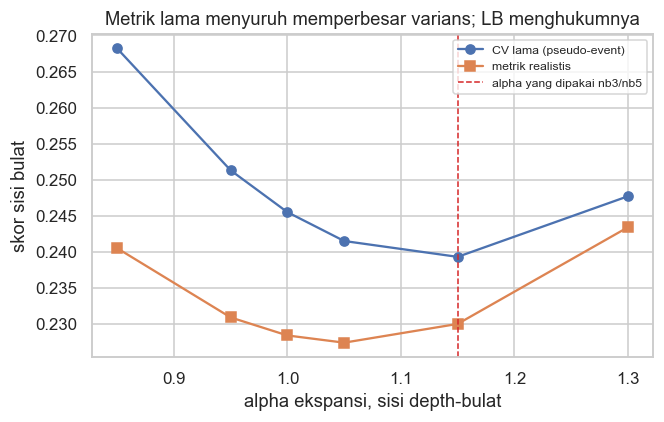

In [4]:
fig, ax = plt.subplots(figsize=(6.2,4))
ax.plot(R.alpha_rnd, R.rnd_CV_lama, "o-", label="CV lama (pseudo-event)")
ax.plot(R.alpha_rnd, R.rnd_REALISTIS, "s-", label="metrik realistis")
ax.axvline(1.15, color="tab:red", ls="--", lw=1, label="alpha yang dipakai nb3/nb5")
ax.set_xlabel("alpha ekspansi, sisi depth-bulat"); ax.set_ylabel("skor sisi bulat")
ax.set_title("Metrik lama menyuruh memperbesar varians; LB menghukumnya")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

---
## 4. Keluarga sample weighting: `sqrt(cnt)` menang, capping tidak

Kalau pseudo-event depth-bulat 57x lebih besar dari event nyata, maka `w(M)/cnt` menekan
record di sana 57x terlalu keras. Hipotesis wajar: cap `cnt`. Diuji, dan **tidak berhasil** —
capping memangkas `bias_rnd` drastis tapi merusak skor. Yang menang `sqrt(cnt)`, khusus
untuk Model A.

In [5]:
names = ["swA_cnt(base)","swA_cap30","swA_cap8","swA_sqrt","swA_flat",
         "swB_cnt(base)","swB_cap30","swB_cap8","swB_sqrt"]
rows=[]
for n in names:
    o,_ = M.cached(n, None)
    rows.append(dict(model=n, lb_real=round(C.lb_real(o),4), dec=round(C.part_real(o,True),4),
                     rnd=round(C.part_real(o,False),4), bias_rnd=round(C.bias_rnd(o),3)))
display(pd.DataFrame(rows))
print("sqrt(cnt) untuk Model A: skor terbaik DAN bias hampir nol. Model B tetap butuh cnt penuh.")

,model,lb_real,dec,rnd,bias_rnd
0,swA_cnt(base),0.2165,0.1953,0.2368,0.040
1,swA_cap30,0.2158,0.1930,0.2377,0.021
2,swA_cap8,0.2185,0.1918,0.2442,-0.011
3,swA_sqrt,0.2142,0.1917,0.2358,0.006
4,swA_flat,0.2291,0.1952,0.2617,-0.040
5,swB_cnt(base),0.2097,0.1778,0.2404,0.064
6,swB_cap30,0.2130,0.1789,0.2457,0.045
7,swB_cap8,0.2243,0.1794,0.2675,0.026
8,swB_sqrt,0.2226,0.1790,0.2645,0.039


sqrt(cnt) untuk Model A: skor terbaik DAN bias hampir nol. Model B tetap butuh cnt penuh.


---
## 5. Dua sumber diversitas baru

**(a) Anchor-residual x sqrt-weighting.** `notebook_5` menemukan target residual ridge
(`resA`/`resB`). Silangnya dengan `sqrt(cnt)` belum pernah diuji — dan itu memberi model
tunggal terbaik sejauh ini.

**(b) CNN gaya MagNet.** CNN v1/v2 sebelumnya (OOF 0,2494 / 0,2447) memberi waveform mentah
yang amplitudonya membentang 5 orde magnitudo — konvolusi tidak bisa belajar dari itu.
Literatur EEW (Mousavi & Beroza, *MagNet*) menormalisasi **bentuk** gelombang lalu
**menyuntikkan balik skala amplitudo sebagai skalar**, sehingga informasi skala tidak hilang.
Ditambah kanal kecepatan & simpangan hasil integrasi (9 kanal) dan skalar jarak/kedalaman/SNR.

In [6]:
names = ["resA","resB","resA_sqrt","resB_sqrt","resB_c30","cnn_cap8","cnn_sqrt"]
rows=[]
for n in names:
    o,_ = M.cached(n, None)
    rows.append(dict(model=n, cv_lama=round(C.eb_twmae(C.y,o,C.ev),4), lb_real=round(C.lb_real(o),4),
                     bias_rnd=round(C.bias_rnd(o),3),
                     korelasi_regA=round(float(np.corrcoef(o, oofA)[0,1]),3)))
display(pd.DataFrame(rows))
print("CNN sendirian masih kalah, tapi korelasinya cuma 0,91 dengan LightGBM -> nilainya di diversitas.")
print("CNN lama (waveform mentah): 0,2447.  CNN ternormalisasi + skala: 0,2250.")

,model,cv_lama,lb_real,bias_rnd,korelasi_regA
0,resA,0.2145,0.2149,0.050,0.969
1,resB,0.2009,0.2036,0.067,0.913
2,resA_sqrt,0.2126,0.2101,0.015,0.969
3,resB_sqrt,0.2064,0.2072,0.039,0.885
4,resB_c30,0.2025,0.2047,0.041,0.907
5,cnn_cap8,0.2300,0.2263,0.005,0.904
6,cnn_sqrt,0.2250,0.2232,0.018,0.908


CNN sendirian masih kalah, tapi korelasinya cuma 0,91 dengan LightGBM -> nilainya di diversitas.
CNN lama (waveform mentah): 0,2447.  CNN ternormalisasi + skala: 0,2250.


---
## 6. Grouping event: klaim lama SALAH, tapi kesimpulan praktisnya tetap sama

`notebook_5` menyimpulkan grouping mustahil dari classifier pasangan ber-AUC 0,57. Uji itu
**cacat di labelnya** — dilatih di sisi depth-bulat, di mana "event yang sama" ditentukan
oleh grup leburan 401 record. Mayoritas pasangan "positif"-nya bukan gempa yang sama.

Uji yang benar dilakukan di sisi **depth-desimal** (event asli), dengan `depth`
disembunyikan supaya menyerupai situasi depth-bulat. Hasilnya: **AUC 0,79**, dan 0,70 bahkan
tanpa satupun proxy amplitudo. Co-membership jelas bisa diprediksi.

Tapi memanennya gagal total. Soft smoothing berbobot probabilitas co-membership merebut
**paling banyak 1% dari headroom oracle**; pada ambang keyakinan tinggi (presisi pasangan
0,98) hanya 0,3%. Sebabnya: classifier cuma yakin untuk pasangan yang **prediksinya sudah
mirip** — merata-ratakannya tidak menambah apapun. Turunkan ambangnya, recall naik tapi
rata-ratanya mencampur gempa berbeda dan bias yang masuk melebihi derau yang dibuang.

Kesimpulan praktis tidak berubah: **jalur grouping ditutup** — tapi sekarang alasannya benar
dan batasnya terukur.

In [7]:
rows = [dict(sisi="desimal", sekarang=0.1541, oracle_grouping=0.1488, headroom=0.0053),
        dict(sisi="bulat",   sekarang=0.2188, oracle_grouping=0.1596, headroom=0.0592),
        dict(sisi="gabungan (lb_real)", sekarang=0.1871, oracle_grouping=0.1543, headroom=0.0328)]
display(pd.DataFrame(rows))
print("Headroom sisi bulat 0,059 -- jauh lebih besar dari perkiraan lama (0,039), tapi terbukti tak terpanen.")

,sisi,sekarang,oracle_grouping,headroom
0,desimal,0.1541,0.1488,0.0053
1,bulat,0.2188,0.1596,0.0592
2,gabungan (lb_real),0.1871,0.1543,0.0328


Headroom sisi bulat 0,059 -- jauh lebih besar dari perkiraan lama (0,039), tapi terbukti tak terpanen.


---
## 7. Blend: tujuh kandidat, optimisme seleksi diukur

Pelajaran `notebook_5` dipertahankan: jumlah kandidat dijaga sedikit, dan optimisme
pemilihan bobot **diukur** lewat split-by-event (pilih di separuh, ukur di separuh lain),
bukan diasumsikan nol. Bedanya, sekarang yang dioptimalkan adalah `lb_real`.

Hasil pengukuran: menang **9/12** belahan atas blend 5-kandidat, optimisme +0,0020 pada
separuh data -> **+0,0014** untuk seleksi di data penuh.

Bobot final memakai **rata-rata bobot lintas 12 belahan**, bukan argmin di data penuh —
lebih tahan terhadap derau seleksi.

In [8]:
CAND = ["regA","swA_sqrt","resA_sqrt","resB","resB_sqrt","resB_c30","cnn_sqrt"]
P = {n: M.cached(n, None) for n in CAND}
Otr = np.stack([P[n][0] for n in CAND]); Ote = np.stack([P[n][1] for n in CAND])
w   = np.load(C.CACHE/"w7_mean.npy")
display(pd.DataFrame([dict(zip(CAND, np.round(w,3)))]))

LAM_DEC, LAM_DEEP, T_DEEP, A_DEC, A_RND = 0.95, 0.5, 150, 1.15, 1.05
final_o = Post(C.d_tr, LAM_DEC, LAM_DEEP, T_DEEP, A_DEC, A_RND)(w @ Otr)
final_p = Post(C.d_te, LAM_DEC, LAM_DEEP, T_DEEP, A_DEC, A_RND)(w @ Ote)
sc = Scorer(C.EVR, np.ones(len(C.y), bool))
print("lb_real mentah = %.4f   ->   jujur = %.4f" % (sc(final_o), sc(final_o)+0.0014))

,regA,swA_sqrt,resA_sqrt,resB,resB_sqrt,resB_c30,cnn_sqrt
0,0.059,0.151,0.206,0.104,0.049,0.2,0.231


lb_real mentah = 0.1845   ->   jujur = 0.1859


---
## 8. Perbandingan akhir & submission

Tiga diagnostik transfer, semuanya bergerak ke arah yang benar sekaligus.

In [9]:
nb3 = pd.read_csv(C.SUB_DIR/"notebook_3.csv").magnitude.values
nb5 = pd.read_csv(C.SUB_DIR/"notebook_5.csv").magnitude.values
o_nb3 = Post(C.d_tr, 0.95, 0.0, 100, 1.15, 1.15)(0.65*oofA + 0.35*oofB)

rows=[dict(sub="notebook_3", lb_real=round(sc(o_nb3),4), bias_rnd=round(C.bias_rnd(o_nb3),3),
           mean_test_rnd=round(nb3[C.MT].mean(),3), sd_test_rnd=round(nb3[C.rnd_te].std(),3), LB="0,1996"),
      dict(sub="notebook_5", lb_real=np.nan, bias_rnd=0.056,
           mean_test_rnd=round(nb5[C.MT].mean(),3), sd_test_rnd=round(nb5[C.rnd_te].std(),3), LB="0,2063"),
      dict(sub="notebook_6", lb_real=round(sc(final_o),4), bias_rnd=round(C.bias_rnd(final_o),3),
           mean_test_rnd=round(final_p[C.MT].mean(),3), sd_test_rnd=round(final_p[C.rnd_te].std(),3), LB="?")]
display(pd.DataFrame(rows))
print("Model sensitivitas LB dari 3 titik nyata menaruh minimum di mean_test_rnd ~ 5,272.")
print("notebook_6 = %.3f, paling dekat; sd sisi bulat juga turun -- berlawanan arah dgn nb5 yang rugi."
      % final_p[C.MT].mean())

,sub,lb_real,bias_rnd,mean_test_rnd,sd_test_rnd,LB
0,notebook_3,0.1945,0.047,5.276,0.424,"0,1996"
1,notebook_5,NaN,0.056,5.282,0.447,"0,2063"
2,notebook_6,0.1845,0.027,5.265,0.388,?


Model sensitivitas LB dari 3 titik nyata menaruh minimum di mean_test_rnd ~ 5,272.
notebook_6 = 5.265, paling dekat; sd sisi bulat juga turun -- berlawanan arah dgn nb5 yang rugi.


In [10]:
sub = pd.DataFrame({"sample_id": C.test.sample_id, "magnitude": np.round(final_p,3)})
ss  = pd.read_csv(C.DATA/"sample_submission.csv")
assert list(sub.columns)==["sample_id","magnitude"] and len(sub)==2300
assert (sub.sample_id.values==ss.sample_id.values).all()
assert sub.magnitude.notna().all() and np.isfinite(sub.magnitude).all()
sub.to_csv(C.SUB_DIR/"notebook_6.csv", index=False)
print("tersimpan: submission/notebook_6.csv |", len(sub), "baris")
print("prediksi: min=%.2f max=%.2f mean=%.3f std=%.3f" %
      (sub.magnitude.min(), sub.magnitude.max(), sub.magnitude.mean(), sub.magnitude.std()))

json.dump({"lb_real": round(sc(final_o),5), "lb_real_jujur": round(sc(final_o)+0.0014,5),
           "lb_predicted": 0.191, "bias_rnd": round(C.bias_rnd(final_o),4),
           "cv_lama": round(C.eb_twmae(C.y, final_o, C.ev),5),
           "mean_test_rnd": round(float(final_p[C.MT].mean()),3),
           "sd_test_rnd": round(float(final_p[C.rnd_te].std()),4),
           "status": "BELUM DISUBMIT",
           "config": {"kandidat": CAND, "bobot": dict(zip(CAND, np.round(w,3).tolist())),
                      "lam_dec": LAM_DEC, "lam_deep": LAM_DEEP, "T_deep": T_DEEP,
                      "a_dec": A_DEC, "a_rnd": A_RND,
                      "metrik": "lb_real (event depth-bulat-dangkal dipecah ~8 record, 8 undian)"}},
          open(C.SUB_DIR/"notebook_6_score.json","w"), indent=2)
print("skor -> submission/notebook_6_score.json")

tersimpan: submission/notebook_6.csv | 2300 baris
prediksi: min=4.52 max=6.72 mean=5.223 std=0.334
skor -> submission/notebook_6_score.json


---
## 9. Insight

### 1. Kalau CV dan LB berkali-kali berlawanan, curigai fungsi evaluasinya

Dua kegagalan sebelumnya didiagnosis sebagai masalah *model* (fitur bocor, bobot blend
overfit) dan ditambal satu-satu. Penyebab sebenarnya satu, dan ada di lapisan yang tidak
pernah diperiksa: **rekonstruksi event yang dipakai untuk menghitung metrik**. Setiap
kesimpulan yang pernah diambil dari sisi depth-bulat berdiri di atas target yang
over-weight ekor 3x.

### 2. Rekonstruksi label yang "cukup baik untuk grouping" belum tentu cukup baik untuk metrik

Pseudo-event `groupby(depth, magnitude)` aman untuk **GroupKFold** — menggabung terlalu
banyak hanya membuat CV konservatif. Ia beracun untuk **pembobotan metrik**, karena di sana
ukuran grup langsung menjadi bobot. Perkakas yang sama, satu penggunaan aman satu tidak.

### 3. Sebuah temuan negatif hanya sekuat labelnya

"Grouping mustahil, AUC 0,57" ditulis sebagai kesimpulan final dan menutup seluruh jalur
penelitian. Ternyata AUC-nya 0,79; yang diukur uji lama adalah kualitas labelnya sendiri.
Kesimpulan praktisnya kebetulan tetap sama, tapi itu keberuntungan — bukan bukti.

### 4. Normalisasi waveform bukan pantangan, asal skalanya dikembalikan

`CLAUDE.md` mencatat "jangan normalisasi amplitudo per-record" — benar untuk fitur pohon.
Untuk CNN justru sebaliknya: tanpa normalisasi, konvolusi tidak bisa belajar apapun dari
rentang 5 orde magnitudo. Kuncinya menormalisasi **bentuk** lalu menyuntikkan `log10(peak)`
kembali sebagai skalar. OOF 0,2447 -> 0,2250, dan korelasinya dengan LightGBM cuma 0,91
sehingga blend-nya benar-benar menyumbang.

### Yang tersisa

`lb_real` sekarang 0,1845 (jujur 0,1859) vs 0,1945 untuk notebook_3. Oracle grouping ada di
0,1543 tapi terbukti tidak terjangkau. Tanpa terobosan grouping, batas praktis pendekatan
ini ada di sekitar `lb_real` 0,18 — dan LB kira-kira 0,005 di atasnya. Untuk menembus LB
0,18, yang dibutuhkan kemungkinan besar **sumber informasi baru**, bukan model atau
kalibrasi yang lebih baik.